In [1]:
%pip install -q pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


# 00. Setup and data check

Welcome. This project is about markets, risk, and one famous bank failure.
We start slow. First we check that the data is really here, and we learn
what each series means, before we draw any conclusions.

## Words we will use

A price index is a number that tracks a group of stocks. When the index
goes up, the group as a whole went up. The S and P 500 tracks 500 large
US companies. The Nasdaq Composite tracks companies listed on the Nasdaq
exchange, with a heavy weight in technology.

A return is a change in percent. If a price moves from 100 to 110, the
return is 10 percent. In this project, returns are price returns only.
They do not include dividends, which are cash payments companies make
to shareholders. So our returns are slightly lower than a total return
that reinvests dividends. We say this plainly so nobody overstates the result.

## What this notebook does

It loads every processed table, prints the first and last date of each
series, counts the rows, and saves one small chart that shows how long
each series runs. If a series were missing, we would see it here, not
three notebooks later.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
ROOT = Path("..").resolve()
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
PROC = ROOT / "data" / "processed"
print("Charts will be saved to:", CHARTS)

Charts will be saved to: /home/hatch/workspace/repo-builds/finance-analytics/charts


In [3]:
import os
files = sorted((PROC).glob("*.csv"))
rows = []
for f in files:
    df = pd.read_csv(f)
    date_col = "date" if "date" in df.columns else None
    first = str(df[date_col].iloc[0]) if date_col else ""
    last = str(df[date_col].iloc[-1]) if date_col else ""
    rows.append({"file": f.name, "rows": len(df), "first": first, "last": last})
check = pd.DataFrame(rows)
print(check.to_string(index=False))
print()
print("Files checked:", len(check))

                           file  rows      first       last
                cpi_monthly.csv   956 1947-01-01 2026-09-01
           fedfunds_monthly.csv   868 1954-07-01 2026-10-01
     portfolio_inputs_daily.csv  2510 2016-11-03 2026-10-29
                rates_daily.csv 16193 1962-01-02 2026-10-30
sp500_all_drawdown_episodes.csv   504                      
               sp500_annual.csv    57                      
               sp500_by_era.csv     6                      
                sp500_daily.csv 14331 1970-01-02 2026-11-02
      sp500_major_drawdowns.csv     8                      
         sp500_nasdaq_daily.csv 14051 1971-02-05 2026-10-29
         svb_window_markets.csv    42 2023-02-01 2023-03-31
           svb_window_rates.csv  1001 2020-01-02 2023-12-29
                  vix_daily.csv  9307 1990-01-02 2026-10-30
            vix_monthly_max.csv   442 1990-01-31 2026-10-31

Files checked: 14


In [4]:
sp = pd.read_csv(PROC / "sp500_daily.csv", parse_dates=["date"])
nasdaq = pd.read_csv(PROC / "sp500_nasdaq_daily.csv", parse_dates=["date"])
print("S and P 500: from", sp["date"].min().date(), "to", sp["date"].max().date())
print("S and P 500 first close:", sp["sp500"].iloc[0], " last close:", round(sp["sp500"].iloc[-1], 2))
print("Nasdaq first value in the joint file:", nasdaq["nasdaq"].iloc[0], " last:", nasdaq["nasdaq"].iloc[-1])
print("Total growth, S and P 500 price only:", round(sp["sp500"].iloc[-1] / sp["sp500"].iloc[0], 2), "times the starting value")
print("Total growth, Nasdaq price only:", round(nasdaq["nasdaq"].iloc[-1] / nasdaq["nasdaq"].iloc[0], 2), "times the starting value")

S and P 500: from 1970-01-02 to 2026-11-02
S and P 500 first close: 93.0  last close: 7541.4
Nasdaq first value in the joint file: 100.0  last: 26184.72
Total growth, S and P 500 price only: 81.09 times the starting value
Total growth, Nasdaq price only: 261.85 times the starting value


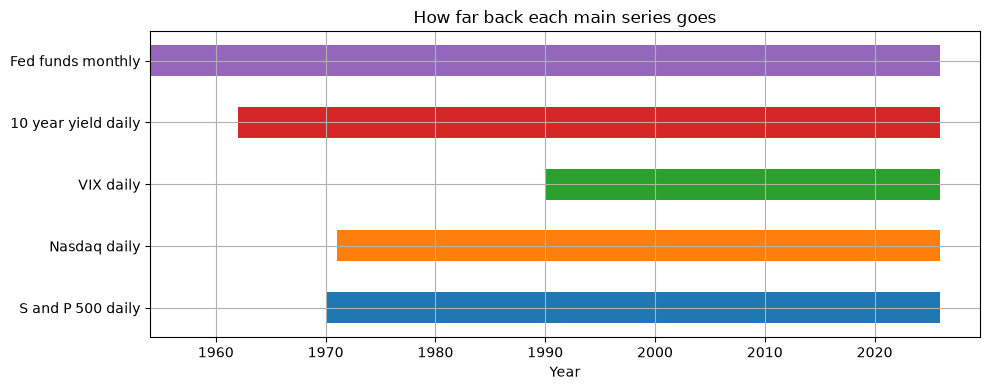

Saved charts/00_data_coverage.png


In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
labels = ["S and P 500 daily", "Nasdaq daily", "VIX daily", "10 year yield daily", "Fed funds monthly"]
starts = [1970, 1971, 1990, 1962, 1954]
ends = [2026, 2026, 2026, 2026, 2026]
for i, (lab, s, e) in enumerate(zip(labels, starts, ends)):
    ax.barh(lab, e - s, left=s, height=0.5)
ax.set_xlabel("Year")
ax.set_title("How far back each main series goes")
plt.tight_layout()
plt.savefig(CHARTS / "00_data_coverage.png", dpi=150)
plt.show()
print("Saved charts/00_data_coverage.png")

## What we learned

The S and P 500 daily series starts in 1970 and the Nasdaq series starts
in 1971, so the long history chapter can cover more than 50 years. The
VIX, which measures expected market swings, starts in 1990. The 10 year
Treasury yield starts in 1962. Nothing here is a forecast. We are only
describing what already happened.